In [1]:
from matplotlib import pyplot as plt
import numpy as np
from scipy.special import jv, kv
from scipy.special import j1 # Bessel function of the first kind of order 1, for the diffraction pattern calculation
from scipy.optimize import root_scalar
from scipy.constants import c, epsilon_0, mu_0, pi
import scipy.integrate as integrate
import math

In [2]:
# jn_zeros is a function that returns the zeros of the Bessel function of the first kind, 
# which are needed to find the roots for the LP01 mode in a step-index fibre
from scipy.special import jn_zeros  # NEW: needed to get the first zero of J0

In [3]:
import sys
from pathlib import Path
import joblib
import time

src_path = Path("/Users/tliu/oh_suppression/codes/src")

if str(src_path) not in sys.path:
    sys.path.append(str(src_path))

from oh_suppression.coupling import *

In [4]:
from oh_suppression.point_source_coupling import *
from oh_suppression.flat_background_coupling import *
from oh_suppression.extended_source_coupling import *

In [5]:
from oh_suppression.point_source_coupling import *
from oh_suppression.image_plane_fields import *

In [6]:
from matplotlib import pyplot as plt
import numpy as np
from scipy import special #import jv, kv
# from scipy.special import j1 # Bessel function of the first kind of order 1, for the diffraction pattern calculation
from scipy.optimize import root_scalar
from scipy.constants import c, epsilon_0, mu_0, pi
import scipy.integrate as integrate
# jn_zeros is a function that returns the zeros of the Bessel function of the first kind, 
# which are needed to find the roots for the LP01 mode in a step-index fibre
from scipy.special import jn_zeros  # NEW: needed to get the first zero of J0
from scipy.optimize import brentq
from scipy.optimize import fminbound
from dataclasses import dataclass
import pandas as pd
from joblib import Parallel, delayed
import os

In [7]:
import astropy.units as u

from astropy.modeling.models import Sersic2D
# Source: https://docs.astropy.org/en/stable/api/astropy.modeling.functional_models.Sersic2D.html

In [8]:
r_max = 125e-6
n_grid = 1000

x_1d = np.linspace(-r_max, r_max, n_grid)
y_1d = np.linspace(-r_max, r_max, n_grid)

x, y = np.meshgrid(x_1d, y_1d)

In [9]:
rad_to_arcsec = (180 / np.pi) * 3600 
rad_to_arcsec

206264.80624709636

In [10]:
def sigma_jitter_milliarcsec_to_metres(sigma_jitter_rms, focal_length, demagnification): 
    """
    Convert the RMS jitter from milliarcseconds to metres at the fibre plane.

    Parameters: 
    sigma_jitter_rms : float
        RMS jitter in milliarcseconds.
    focal_length : float
        Focal length of the telescope in metres.
    demagnification : float 
        Demagnification factor from the telescope focal plane to the fibre plane, done by the reimaging optics. 

    Returns:
    float
        RMS jitter in metres at the fibre plane.
    """
    rad_to_arcsec = (180 / np.pi) * 3600 # essentially, 1 radian = 206264.80624709636 arcseconds

    # Convert jitter from milliarcseconds to radians
    sigma_theta_radians = sigma_jitter_rms * 1e-3 / rad_to_arcsec 

    # Convert jitter from radians to physical units (metres) at the fibre plane using the focal length and demagnification

    sigma_jitter_metres = demagnification * focal_length * sigma_theta_radians

    return sigma_jitter_metres

In [11]:
def extract_mode_field(prepared_modes, l, m, angular=None):
    """
    Extract the electric-field and intensity arrays for one LP mode.

    Parameters
    ----------
    prepared_modes : list
        Output from prepare_modes_2d().

    l : int
        Azimuthal mode number.

    m : int
        Radial mode number.

    angular : str or None
        "cos" or "sin".

        For l = 0, angular can be left as None because only one
        angular component exists.

        For l != 0, specify "cos" or "sin".

    Returns
    -------
    E_mode : 2D numpy.ndarray
        Electric-field amplitude.

    I_mode : 2D numpy.ndarray
        Mode intensity |E_mode|^2.
    """

    matching_modes = [
        mode for mode in prepared_modes
        if mode["l"] == l and mode["m"] == m
    ]

    if angular is not None:
        matching_modes = [
            mode for mode in matching_modes
            if mode["angular"] == angular
        ]

    if len(matching_modes) == 0:
        raise ValueError(
            f"LP{l}{m}"
            + (f" {angular}" if angular is not None else "")
            + " was not found."
        )

    # l != 0 has both cos and sin components,
    # so require the user to choose one.
    if len(matching_modes) > 1:
        raise ValueError(
            f"LP{l}{m} has multiple angular components. "
            "Specify angular='cos' or angular='sin'."
        )

    mode = matching_modes[0]

    return mode["E_mode"], mode["I_mode"]

In [ ]:
# def psf_2d_decentre_map(
#         prepared_modes,
#         x, y, x_1d, y_1d, 
#         lam0, F_eff, alpha, 
#         decentre_x_1d, 
#         decentre_y_1d,
#         E_S = 1.0, 
#         compute_portion="Full", 
#         return_mode_maps=False, 
#         n_jobs=1
# ): 
#     """
#     Calculate point-source coupling efficiency over a 2D grid of PSF decentre positions relative to the fibre centre.

#     Parameters:
#     prepared_modes : list
#             Output from prepare_modes_2d() for ONE fibre core radius.
    
#         x, y : 2D arrays
#             Coordinate grids at the fibre input plane [m].
    
#         x_1d, y_1d : 1D arrays
#             Coordinate axes corresponding to x and y [m].
    
#         lam0 : float
#             Wavelength [m].
    
#         F_eff : float
#             Effective focal ratio.
    
#         alpha : float
#             Central obstruction ratio.
    
#         decentre_x_1d : 1D array
#             PSF x-offset positions [m].
    
#         decentre_y_1d : 1D array
#             PSF y-offset positions [m].
    
#         E_S : float
#             Source electric-field amplitude.
    
#         return_mode_maps : bool
#             If True, also store a 2D eta map for each individual mode.
    
#         n_jobs : int
#             Number of parallel workers.
    
#         Returns
#         -------
#         eta_total_map : 2D ndarray
#             Total coupling efficiency at every (dx, dy).
    
#             Shape:
#                 (len(decentre_y_1d), len(decentre_x_1d))
    
#         mode_eta_maps : dict or None
#             If return_mode_maps=True, dictionary containing the
#             coupling map for each individual mode.

#     """
#     if compute_portion == "Full":
#         # Perform full computation, check if range from (-r_max, r_max) is sufficient to cover the entire PSF decentre range
#         r_max = max(abs(x_1d).max(), abs(y_1d).max())
#         if (r_max < abs(decentre_x_1d).max()) or (r_max < abs(decentre_y_1d).max()):
#             raise ValueError("The coordinate range is not sufficient to cover the entire PSF decentre range.")
#         pass
#     elif compute_portion == "Quadrant":
#         # Perform partial computation, mirror along x and y axes to fill in the rest of the grid, check if range from (0, r_max) is sufficient to cover the entire PSF decentre range
#         if decentre_x_1d.min() < 0 or decentre_y_1d.min() < 0:
#             raise ValueError("For 'Quadrant' computation, decentre_x_1d and decentre_y_1d must be non-negative.")
#         pass
#     else:
#         raise ValueError("compute_portion must be either 'Full' or 'Quadrant'")

#     nx = len(decentre_x_1d)
#     ny = len(decentre_y_1d)

#     # Prepare storage for individual mode maps if requested
#     if return_mode_maps:
#         mode_eta_maps = {}

#         for mode in prepared_modes: 

#             key = (mode["l"], mode["m"], mode["angular"])

#             mode_eta_maps[key] = np.zeros((ny, nx))

#     else: 
#         mode_eta_maps = None

#     # Calcualte one horizontal row of the decentre map 
#     def calculate_row(dy): 

#         eta_row = np.zeros(nx)

#         if return_mode_maps: 
#             mode_rows = { key: np.zeros(nx) for key in mode_eta_maps.keys() }
        
#         else: 
#             mode_rows = None

#         for ix, dx in enumerate(decentre_x_1d): 

#             eta_total, mode_results = total_eff_2d(
#                 prepared_modes=prepared_modes, 
#                 x=x, y=y, 
#                 x_1d=x_1d, y_1d=y_1d,
#                 lam0=lam0, F_eff=F_eff, alpha=alpha,
#                 decentre_x=dx, decentre_y=dy,
#                 E_S=E_S,
#             )

#             eta_row[ix] = eta_total

#             if return_mode_maps: 

#                 for result in mode_results: 

#                     key = (result["ArithmeticError"], result["m"], result["angular"])

#                     mode_rows[key][ix] = result["eta"]

#     return eta_row, mode_rows


# # Calculate every y row in parallel
#     if n_jobs == 1:

#         eta_total_map = np.zeros((ny, nx))

#         for iy, dy in enumerate(decentre_y_1d):

#             eta_row, mode_rows = calculate_row(dy)

#             eta_total_map[iy, :] = eta_row

#             if return_mode_maps:

#                 for key in mode_eta_maps:
#                     mode_eta_maps[key][iy, :] = mode_rows[key]

#             print(
#                 f"{iy + 1}/{ny} rows complete "
#                 f"({100 * (iy + 1) / ny:.1f}%)"
#             )

#     else:

#         results = Parallel(
#             n_jobs=n_jobs,
#             verbose=10
#         )(
#             delayed(calculate_row)(dy)
#             for dy in decentre_y_1d
#         )

#         eta_total_map = np.array(
#             [result[0] for result in results]
#         )

#         if return_mode_maps:

#             for key in mode_eta_maps:

#                 mode_eta_maps[key] = np.array([
#                     result[1][key]
#                     for result in results
#                 ])

#     return eta_total_map, mode_eta_maps





In [ ]:
# def psf_2d_decentre_map(
#         a,
#         x, y,
#         x_1d, y_1d,
#         lam0,NA, F_eff,
#         alpha,
#         decentre_x_1d,
#         decentre_y_1d,
#         E_S=1.0,
#         mode_case="few_mode",
#         n_jobs=1
# ):
#     """
#     Calculate 2D point-source coupling maps for ONE fibre core radius.

#     Method
#     ------
#     l = 0:
#         Calculate eta(r) along +x and interpolate the radially
#         symmetric result onto the full 2D decentre grid.

#     l != 0:
#         Explicitly calculate cosine and sine coupling maps in the
#         positive quadrant, then mirror them into the full plane.

#     Parameters
#     ----------
#     a : float
#         Fibre core radius [m].

#     prepared_modes : list
#         Output from prepare_modes_2d() for this fibre core radius.

#     x, y : 2D arrays
#         Overlap-integration grid [m].

#     x_1d, y_1d : 1D arrays
#         Coordinate axes of overlap-integration grid [m].

#     decentre_x_1d, decentre_y_1d : 1D arrays
#         Non-negative PSF decentre coordinates [m].
#         Both must begin at zero.

#     Returns
#     -------
#     result : dict
#         {
#             "a": fibre core radius,
#             "eta_total_map": full 2D total coupling map,
#             "mode_eta_maps": {
#                 (l, m, angular): full 2D mode-component map
#             }
#         }
#     """

#     # Prepare all supported modes for this core radius
#     prepared_modes = prepare_modes_2d(
#         x, y,
#         a=a,
#         NA=NA,
#         lam0=lam0,
#         az_sym=False,
#         mode_case=mode_case
#     )

#     decentre_x_1d = np.asarray(decentre_x_1d)
#     decentre_y_1d = np.asarray(decentre_y_1d)

#     # ----------------------------------------------------------
#     # Check quadrant coordinates
#     # ----------------------------------------------------------

#     if (
#         np.any(decentre_x_1d < 0)
#         or np.any(decentre_y_1d < 0)
#     ):
#         raise ValueError(
#             "decentre_x_1d and decentre_y_1d "
#             "must contain only non-negative values."
#         )

#     if (
#         not np.isclose(decentre_x_1d[0], 0.0)
#         or not np.isclose(decentre_y_1d[0], 0.0)
#     ):
#         raise ValueError(
#             "decentre_x_1d and decentre_y_1d "
#             "must begin at zero."
#         )

#     # ----------------------------------------------------------
#     # Split symmetric and asymmetric modes
#     # ----------------------------------------------------------

#     symmetric_modes = [
#         mode for mode in prepared_modes
#         if mode["l"] == 0
#     ]

#     asymmetric_modes = [
#         mode for mode in prepared_modes
#         if mode["l"] != 0
#     ]

#     # ----------------------------------------------------------
#     # Construct full decentre grid
#     # ----------------------------------------------------------

#     decentre_x_full = np.concatenate(
#         (
#             -decentre_x_1d[1:][::-1],
#             decentre_x_1d
#         )
#     )

#     decentre_y_full = np.concatenate(
#         (
#             -decentre_y_1d[1:][::-1],
#             decentre_y_1d
#         )
#     )

#     DX_full, DY_full = np.meshgrid(
#         decentre_x_full,
#         decentre_y_full
#     )

#     mode_eta_maps = {}

#     # ==========================================================
#     # l = 0 modes
#     # ==========================================================

#     # Radial sampling must extend to the corner of the
#     # final square map.
#     r_max = np.sqrt(
#         decentre_x_full.max()**2
#         +
#         decentre_y_full.max()**2
#     )

#     # Use similar spatial resolution to the 2D map.
#     dx = np.min(np.diff(decentre_x_1d))
#     dy = np.min(np.diff(decentre_y_1d))
#     dr = min(dx, dy)

#     n_r = int(np.ceil(r_max / dr)) + 1

#     radial_decentre_1d = np.linspace(
#         0.0,
#         r_max,
#         n_r
#     )

#     for mode in symmetric_modes:

#         key = (
#             mode["l"],
#             mode["m"],
#             mode["angular"]
#         )

#         eta_radial = np.zeros(n_r)

#         for ir, r in enumerate(radial_decentre_1d):

#             eta_mode, _ = total_eff_2d(
#                 prepared_modes=[mode],
#                 x=x,
#                 y=y,
#                 x_1d=x_1d,
#                 y_1d=y_1d,
#                 lam0=lam0,
#                 F_eff=F_eff,
#                 alpha=alpha,
#                 decentre=(r, 0.0),
#                 E_S=E_S
#             )

#             eta_radial[ir] = eta_mode

#         mode_eta_maps[key] = radial_efficiency_to_2d(
#             radial_decentre_1d,
#             eta_radial,
#             DX_full,
#             DY_full
#         )

#     # ==========================================================
#     # l != 0 modes
#     # ==========================================================

#     if asymmetric_modes:

#         nx = len(decentre_x_1d)

#         mode_keys = [
#             (
#                 mode["l"],
#                 mode["m"],
#                 mode["angular"]
#             )
#             for mode in asymmetric_modes
#         ]

#         # ------------------------------------------------------
#         # Calculate one y-row in the positive quadrant
#         # ------------------------------------------------------

#         def calculate_row(dy):

#             rows = {
#                 key: np.zeros(nx)
#                 for key in mode_keys
#             }

#             for ix, dx in enumerate(decentre_x_1d):

#                 _, mode_results = total_eff_2d(
#                     prepared_modes=asymmetric_modes,
#                     x=x,
#                     y=y,
#                     x_1d=x_1d,
#                     y_1d=y_1d,
#                     lam0=lam0,
#                     F_eff=F_eff,
#                     alpha=alpha,
#                     decentre=(dx, dy),
#                     E_S=E_S
#                 )

#                 for result in mode_results:

#                     key = (
#                         result["l"],
#                         result["m"],
#                         result["angular"]
#                     )

#                     rows[key][ix] = result["eta"]

#             return rows

#         # ------------------------------------------------------
#         # Calculate all quadrant rows
#         # ------------------------------------------------------

#         if n_jobs == 1:

#             row_results = []

#             for iy, dy in enumerate(decentre_y_1d):

#                 row_results.append(
#                     calculate_row(dy)
#                 )

#                 print(
#                     f"{iy + 1}/{len(decentre_y_1d)} rows complete "
#                     f"({100 * (iy + 1) / len(decentre_y_1d):.1f}%)"
#                 )

#         else:

#             row_results = Parallel(
#                 n_jobs=n_jobs,
#                 verbose=10
#             )(
#                 delayed(calculate_row)(dy)
#                 for dy in decentre_y_1d
#             )

#         # ------------------------------------------------------
#         # Mirror quadrant maps
#         # ------------------------------------------------------

#         for key in mode_keys:

#             quadrant_map = np.array([
#                 row[key]
#                 for row in row_results
#             ])

#             # Mirror across y-axis
#             full_x = np.concatenate(
#                 (
#                     quadrant_map[:, 1:][:, ::-1],
#                     quadrant_map
#                 ),
#                 axis=1
#             )

#             # Mirror across x-axis
#             full_map = np.concatenate(
#                 (
#                     full_x[1:, :][::-1, :],
#                     full_x
#                 ),
#                 axis=0
#             )

#             mode_eta_maps[key] = full_map

#     # ==========================================================
#     # Total coupling
#     # ==========================================================

#     eta_total_map = np.zeros_like(
#         next(iter(mode_eta_maps.values()))
#     )

#     for eta_map in mode_eta_maps.values():
#         eta_total_map += eta_map

#     return {
#         "a": a,
#         "eta_total_map": eta_total_map,
#         "mode_eta_maps": mode_eta_maps
#     }

In [73]:
def psf_2d_decentre_map(
        a,
        x, y,
        x_1d, y_1d,
        lam0,
        NA,
        F_eff,
        alpha,
        n_decentre=51,
        E_S=1.0,
        mode_case="few_mode",
        n_jobs=1
):
    """
    Calculate full 2D point-source coupling-efficiency maps
    for ONE fibre core radius.

    For each fibre core radius:
        1. Prepare all supported fibre modes.
        2. Define a full 2D PSF decentre grid from -a to +a.
        3. Calculate the total coupling-efficiency map.
        4. Calculate the individual mode-component maps.

    Parameters
    ----------
    a : float
        Fibre core radius [m].

    x, y : 2D arrays
        Coordinate grids used for the electric-field overlap
        calculations [m].

    x_1d, y_1d : 1D arrays
        Coordinate axes corresponding to x and y [m].

    lam0 : float
        Wavelength [m].

    NA : float
        Fibre numerical aperture.

    F_eff : float
        Effective focal ratio.

    alpha : float
        Central obstruction ratio.

    n_decentre : int
        Number of PSF decentre samples along each axis.

        An odd number is recommended so that (0, 0)
        is explicitly included in the grid.

    E_S : float
        Source electric-field amplitude.

    mode_case : str
        Mode-selection case passed to prepare_modes_2d().

    n_jobs : int
        Number of parallel workers used inside
        eta_psf_2d_decentre_map().

    Returns
    -------
    result : dict

        {
            "a": fibre core radius,

            "eta_total_map":
                2D total coupling-efficiency map,

            "mode_eta_maps":
                {
                    (l, m, angular): 2D mode-component map
                }
        }
    """

    # ---------------------------------------------------------
    # Prepare supported fibre modes for this core radius
    # ---------------------------------------------------------

    prepared_modes = prepare_modes_2d(
        x, y,
        a=a,
        NA=NA,
        lam0=lam0,
        az_sym=False,
        mode_case=mode_case
    )

    # ---------------------------------------------------------
    # Construct the full 2D PSF decentre grid
    #
    # The map spans:
    #
    #   -a <= dx <= +a
    #   -a <= dy <= +a
    #
    # ---------------------------------------------------------

    decentre_x_1d = np.linspace(
        -a,
        a,
        n_decentre
    )

    decentre_y_1d = np.linspace(
        -a,
        a,
        n_decentre
    )

    # ---------------------------------------------------------
    # Calculate total and individual-mode coupling maps
    # ---------------------------------------------------------

    eta_total_map, mode_eta_maps = (
        eta_psf_2d_decentre_map(
            prepared_modes=prepared_modes,
            x=x,
            y=y,
            x_1d=x_1d,
            y_1d=y_1d,
            lam0=lam0,
            F_eff=F_eff,
            alpha=alpha,
            decentre_x_1d=decentre_x_1d,
            decentre_y_1d=decentre_y_1d,
            E_S=E_S,
            return_mode_maps=True,
            n_jobs=n_jobs
        )
    )

    # ---------------------------------------------------------
    # Return only the information required downstream
    # ---------------------------------------------------------

    return {
        "a": a,
        "eta_total_map": eta_total_map,
        "mode_eta_maps": mode_eta_maps
    }

In [46]:
def eta_maps_vs_core_radius(
        core_radius_array,
        x, y,
        x_1d, y_1d,
        NA,
        lam0,
        alpha,
        F_eff,
        n_decentre=50,
        mode_case="few_mode",
        E_S=1.0,
        n_jobs=1,
):
    """
    Calculate 2D point-source coupling maps for each fibre core radius.

    Core radii are processed serially.
    Parallelisation is used only inside psf_2d_decentre_map().

    For each core radius a:
        1. Define the decentre grid from 0 to a.
        2. Calculate the 2D coupling maps.
        3. Store the result for that radius.
    """

    n_total = len(core_radius_array)

    results_all_radius = []

    start_time = time.time()

    for i, a in enumerate(core_radius_array):

        # ------------------------------------------------------
        # Decentre grid for THIS fibre radius
        # ------------------------------------------------------

        decentre_x_1d = np.linspace(
            0.0,
            a,
            n_decentre
        )

        decentre_y_1d = np.linspace(
            0.0,
            a,
            n_decentre
        )

        print(
            f"\nCore radius = {a * 1e6:.2f} µm "
            f"({i + 1}/{n_total})"
        )

        print(
            f"Decentre spacing = "
            f"{(a / (n_decentre - 1)) * 1e6:.3f} µm"
        )

        # ------------------------------------------------------
        # Calculate maps for this radius
        # ------------------------------------------------------

        result = psf_2d_decentre_map(
            a=a,
            x=x,
            y=y,
            x_1d=x_1d,
            y_1d=y_1d,
            NA=NA,
            lam0=lam0,
            F_eff=F_eff,
            alpha=alpha,
            decentre_x_1d=decentre_x_1d,
            decentre_y_1d=decentre_y_1d,
            E_S=E_S,
            mode_case=mode_case,
            n_jobs=n_jobs
        )

        results_all_radius.append(result)

        # ------------------------------------------------------
        # Progress
        # ------------------------------------------------------

        step = i + 1
        percent = int(
            round(100 * step / n_total)
        )

        elapsed_time = (
            time.time() - start_time
        )

        elapsed_minutes = int(
            elapsed_time // 60
        )

        elapsed_seconds = int(
            elapsed_time % 60
        )

        print(
            f"{percent}% complete "
            f"({step}/{n_total}) | "
            f"elapsed: "
            f"{elapsed_minutes} min "
            f"{elapsed_seconds:02d} sec"
        )

    return results_all_radius

In [47]:
core_radius_test = np.array([
    10e-6,
    11e-6
])

In [48]:
5/49.9

0.10020040080160321

In [ ]:
results_test = eta_maps_vs_core_radius(
    core_radius_array=core_radius_test,
    x=x,
    y=y,
    x_1d=x_1d,
    y_1d=y_1d,
    NA=0.1,
    lam0=1.5e-6,
    alpha=0.125,
    F_eff=1 / (2 * np.tan(np.arcsin(0.1))),
    mode_case="few_mode",
    E_S=1.0,
    n_jobs=4
)


Core radius = 10.00 µm (1/2)
Decentre spacing = 0.204 µm


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:   13.3s
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:   19.7s
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:   32.3s
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:   39.8s
[Parallel(n_jobs=4)]: Done  33 tasks      | elapsed:  1.0min
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:  1.2min
[Parallel(n_jobs=4)]: Done  50 out of  50 | elapsed:  1.4min finished


50% complete (1/2) | elapsed: 1 min 34 sec

Core radius = 11.00 µm (2/2)
Decentre spacing = 0.224 µm


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:   13.1s
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:   19.9s
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:   34.1s
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:   41.6s
[Parallel(n_jobs=4)]: Done  33 tasks      | elapsed:  1.0min
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:  1.3min


100% complete (2/2) | elapsed: 3 min 11 sec


[Parallel(n_jobs=4)]: Done  50 out of  50 | elapsed:  1.5min finished


In [52]:
results_test[0]["eta_total_map"].shape

(99, 99)

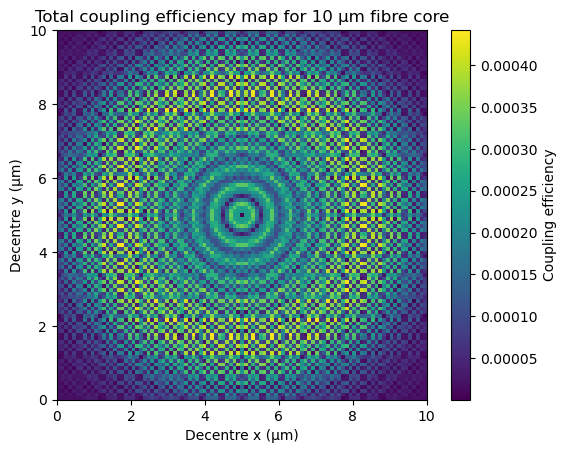

In [57]:
decentre_x_1d = np.linspace(
    0.0,
    core_radius_test[0],
    50
)
decentre_y_1d = np.linspace(
    0.0,
    core_radius_test[0],
    50
)

# Plot the total coupling efficiency map
plt.imshow(results_test[0]["eta_total_map"],
           extent=[
               decentre_x_1d.min() * 1e6,
               decentre_x_1d.max() * 1e6,
               decentre_y_1d.min() * 1e6,
               decentre_y_1d.max() * 1e6
           ],
           origin="lower",
           aspect="equal",
           cmap="viridis"
           )
plt.title("Total coupling efficiency map for 10 µm fibre core")
plt.xlabel("Decentre x (µm)")
plt.ylabel("Decentre y (µm)")
plt.colorbar(label="Coupling efficiency")


In [58]:
def plot_eta_map(eta_map, decentre_x_1d, decentre_y_1d, title):
    plt.figure(figsize=(7, 6))

    plt.imshow(
        eta_map,
        extent=[
            decentre_x_1d.min() * 1e6,
            decentre_x_1d.max() * 1e6,
            decentre_y_1d.min() * 1e6,
            decentre_y_1d.max() * 1e6
        ],
        origin="lower",
        aspect="equal"
    )

    plt.colorbar(label=r"Coupling efficiency, $\eta$")
    plt.xlabel(r"$\Delta x$ (µm)")
    plt.ylabel(r"$\Delta y$ (µm)")
    plt.title(title)
    plt.minorticks_on()
    plt.show()

In [60]:
results_test[0]["mode_eta_maps"]

{(0,
  1,
  'cos'): array([[3.85969909e-07, 3.21713505e-07, 2.49401131e-07, ...,
         2.49401131e-07, 3.21713505e-07, 3.85969909e-07],
        [3.21713505e-07, 2.47741471e-07, 1.83196714e-07, ...,
         1.83196714e-07, 2.47741471e-07, 3.21713505e-07],
        [2.49401131e-07, 1.83196714e-07, 1.79031252e-07, ...,
         1.79031252e-07, 1.83196714e-07, 2.49401131e-07],
        ...,
        [2.49401131e-07, 1.83196714e-07, 1.79031252e-07, ...,
         1.79031252e-07, 1.83196714e-07, 2.49401131e-07],
        [3.21713505e-07, 2.47741471e-07, 1.83196714e-07, ...,
         1.83196714e-07, 2.47741471e-07, 3.21713505e-07],
        [3.85969909e-07, 3.21713505e-07, 2.49401131e-07, ...,
         2.49401131e-07, 3.21713505e-07, 3.85969909e-07]], shape=(99, 99)),
 (0,
  2,
  'cos'): array([[1.12745012e-05, 8.64714963e-06, 6.20306833e-06, ...,
         6.20306833e-06, 8.64714963e-06, 1.12745012e-05],
        [8.64714963e-06, 6.15364645e-06, 4.17504510e-06, ...,
         4.17504510e-06, 6.15

In [62]:
# Plot lp01 and 02 of the 10 µm fibre core
plot_eta_map(
    results_test[0]["mode_eta_maps"][0],
    decentre_x_1d,
    decentre_y_1d,
    title="LP01 mode coupling efficiency map for 10 µm fibre core"
)

KeyError: 0

In [55]:
import matplotlib.pyplot as plt
import numpy as np

def plot_selected_asymmetric_mode_family_maps(
    mode_maps,
    decentre_x_1d,
    decentre_y_1d,
    families,
    cmap="viridis",
    same_scale_per_row=True
):
    """
    Plot cos, sin, and total eta maps for selected asymmetric mode families,
    with one colorbar per row.
    """

    nrows = len(families)

    fig = plt.figure(figsize=(15, 4.2 * nrows))
    gs = fig.add_gridspec(
        nrows=nrows,
        ncols=4,
        width_ratios=[1, 1, 1, 0.05],   # last column for colorbar
        wspace=0.25,
        hspace=0.35
    )

    extent = [
        decentre_x_1d.min() * 1e6,
        decentre_x_1d.max() * 1e6,
        decentre_y_1d.min() * 1e6,
        decentre_y_1d.max() * 1e6
    ]

    for i, (l, m) in enumerate(families):

        eta_cos = mode_maps[(l, m, "cos")]
        eta_sin = mode_maps[(l, m, "sin")]
        eta_total = eta_cos + eta_sin

        maps = [eta_cos, eta_sin, eta_total]
        titles = [
            rf"LP$_{{{l}{m}}}$ cosine",
            rf"LP$_{{{l}{m}}}$ sine",
            rf"LP$_{{{l}{m}}}$ total"
        ]

        if same_scale_per_row:
            vmin = 0.0
            vmax = max(np.max(eta_cos), np.max(eta_sin), np.max(eta_total))
        else:
            vmin = None
            vmax = None

        row_axes = []
        im = None

        for j in range(3):
            ax = fig.add_subplot(gs[i, j])
            row_axes.append(ax)

            im = ax.imshow(
                maps[j],
                extent=extent,
                origin="lower",
                aspect="equal",
                cmap=cmap,
                vmin=vmin,
                vmax=vmax
            )

            ax.set_title(titles[j])
            ax.set_xlabel(r"$\Delta x$ (µm)")
            ax.set_ylabel(r"$\Delta y$ (µm)")
            ax.minorticks_on()

        # dedicated colorbar axis for this row
        cax = fig.add_subplot(gs[i, 3])
        cbar = fig.colorbar(im, cax=cax)
        cbar.set_label(r"Coupling efficiency, $\eta$")

    plt.show()

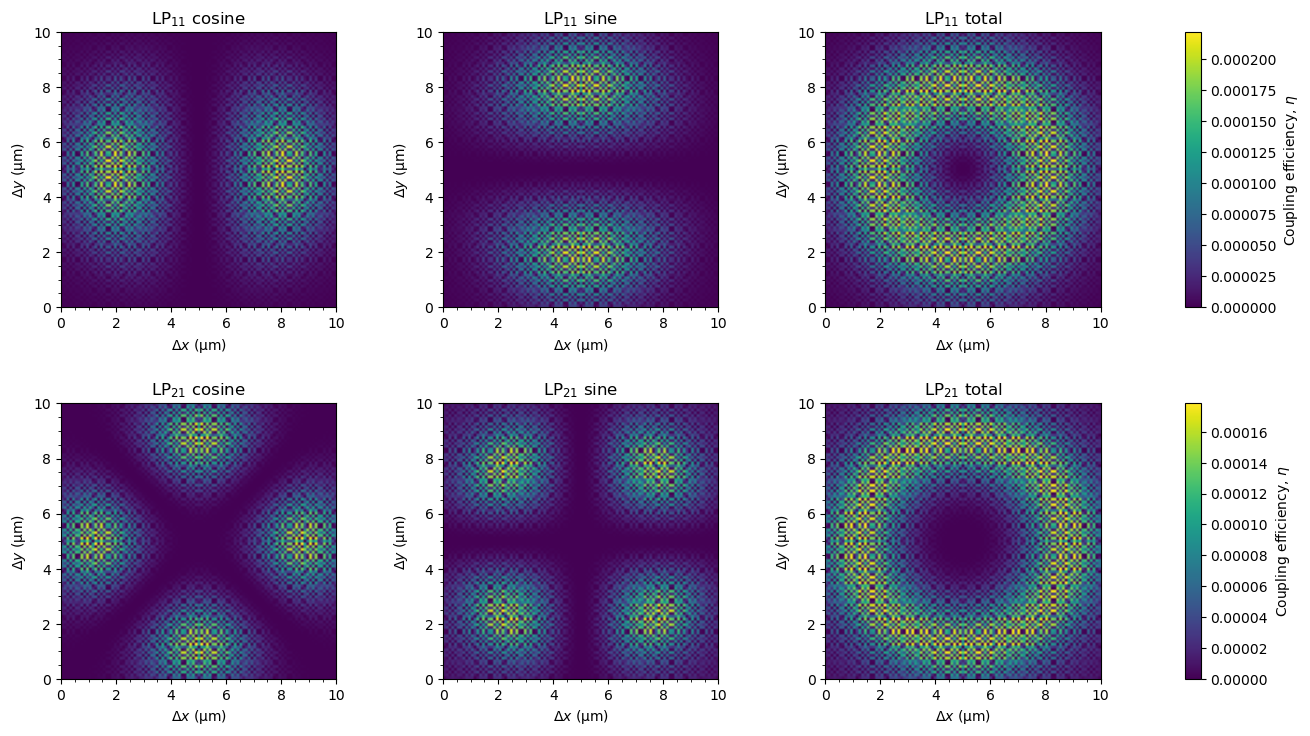

In [56]:
plot_selected_asymmetric_mode_family_maps(
    results_test[0]["mode_eta_maps"],
    decentre_x_1d,
    decentre_y_1d,
    families=sorted({(l, m)
    for (l, m, angular) in results_test[0]["mode_eta_maps"].keys()
    if l != 0})
)

In [64]:
result = psf_2d_decentre_map(
    a=10e-6,
    x=x,
    y=y,
    x_1d=x_1d,
    y_1d=y_1d,
    lam0=1.5e-6,
    NA=0.1,
    F_eff=1 / (2 * np.tan(np.arcsin(0.1))),
    alpha=0.125,
    decentre_x_1d=np.linspace(0.0, 10e-6, 51),
    decentre_y_1d=np.linspace(0.0, 10e-6, 51),
    E_S=1.0,
    mode_case="few_mode",
    n_jobs=1
)

1/51 rows complete (2.0%)
2/51 rows complete (3.9%)
3/51 rows complete (5.9%)
4/51 rows complete (7.8%)
5/51 rows complete (9.8%)
6/51 rows complete (11.8%)
7/51 rows complete (13.7%)
8/51 rows complete (15.7%)
9/51 rows complete (17.6%)
10/51 rows complete (19.6%)
11/51 rows complete (21.6%)
12/51 rows complete (23.5%)
13/51 rows complete (25.5%)
14/51 rows complete (27.5%)
15/51 rows complete (29.4%)
16/51 rows complete (31.4%)
17/51 rows complete (33.3%)
18/51 rows complete (35.3%)
19/51 rows complete (37.3%)
20/51 rows complete (39.2%)
21/51 rows complete (41.2%)
22/51 rows complete (43.1%)
23/51 rows complete (45.1%)
24/51 rows complete (47.1%)
25/51 rows complete (49.0%)
26/51 rows complete (51.0%)
27/51 rows complete (52.9%)
28/51 rows complete (54.9%)
29/51 rows complete (56.9%)
30/51 rows complete (58.8%)
31/51 rows complete (60.8%)
32/51 rows complete (62.7%)
33/51 rows complete (64.7%)
34/51 rows complete (66.7%)
35/51 rows complete (68.6%)
36/51 rows complete (70.6%)
37/51 

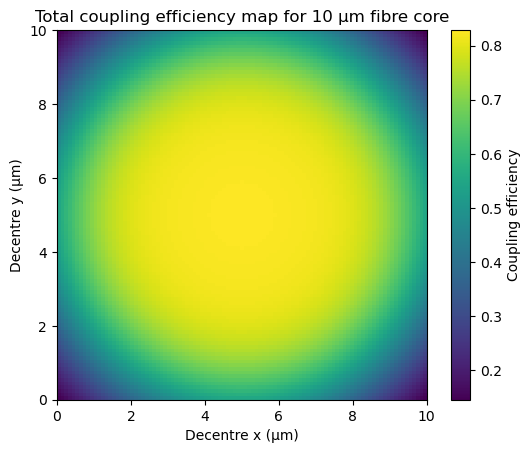

In [71]:
decentre_x_1d = np.linspace(
    0.0,
    10e-6,
    51
)
decentre_y_1d = np.linspace(
    0.0,
    10e-6,
    51
)

# Plot the total coupling efficiency map
plt.imshow(result["eta_total_map"],
           extent=[
               decentre_x_1d.min() * 1e6,
               decentre_x_1d.max() * 1e6,
               decentre_y_1d.min() * 1e6,
               decentre_y_1d.max() * 1e6
           ],
           origin="lower",
           aspect="equal",
           cmap="viridis"
           )
plt.title("Total coupling efficiency map for 10 µm fibre core")
plt.xlabel("Decentre x (µm)")
plt.ylabel("Decentre y (µm)")
plt.colorbar(label="Coupling efficiency")


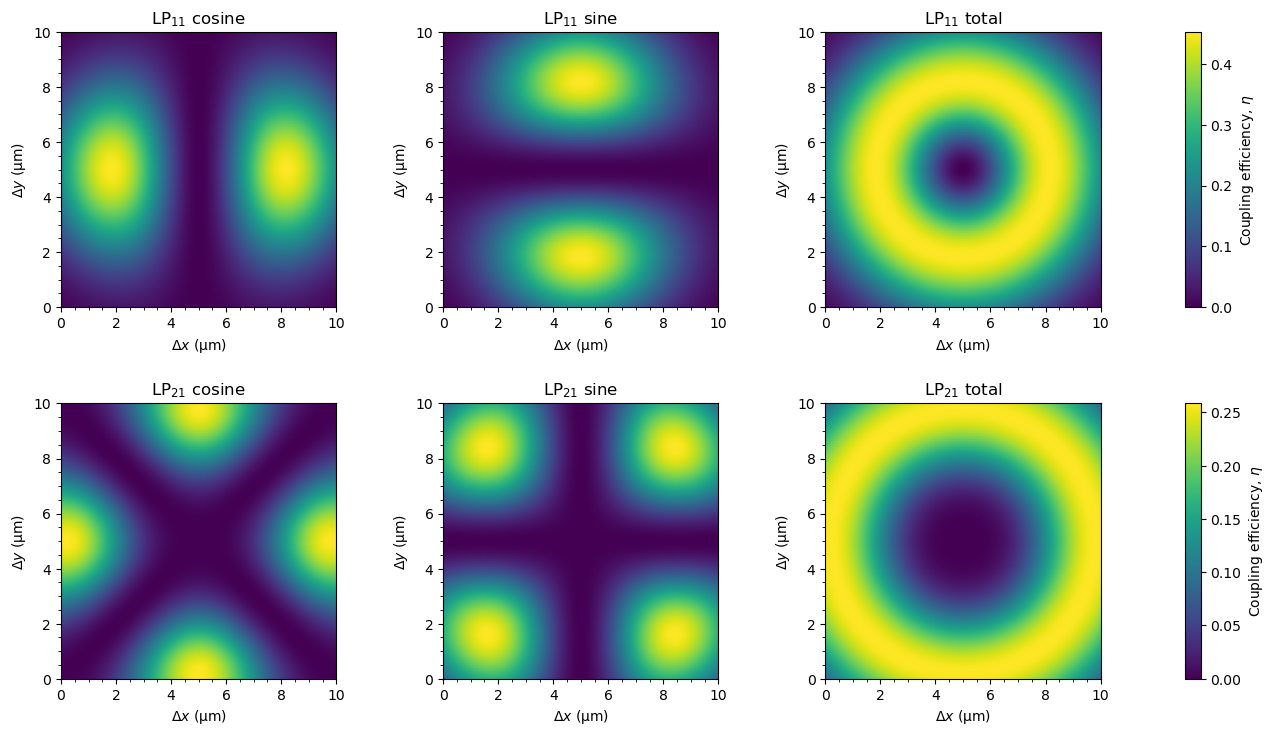

In [ ]:
plot_selected_asymmetric_mode_family_maps(
    result["mode_eta_maps"],
    decentre_x_1d,
    decentre_y_1d,
    families=sorted({(l, m)
    for (l, m, angular) in result["mode_eta_maps"].keys()
    if l != 0})
)

In [74]:
result = psf_2d_decentre_map(
    a=10e-6,
    x=x,
    y=y,
    x_1d=x_1d,
    y_1d=y_1d,
    lam0=1.5e-6,
    NA=0.1,
    F_eff=1 / (
        2 * np.tan(
            np.arcsin(0.1)
        )
    ),
    alpha=0.125,
    n_decentre=51,
    E_S=1.0,
    mode_case="few_mode",
    n_jobs=1
)

1/51 rows complete (2.0%)
2/51 rows complete (3.9%)
3/51 rows complete (5.9%)
4/51 rows complete (7.8%)
5/51 rows complete (9.8%)
6/51 rows complete (11.8%)
7/51 rows complete (13.7%)
8/51 rows complete (15.7%)
9/51 rows complete (17.6%)
10/51 rows complete (19.6%)
11/51 rows complete (21.6%)
12/51 rows complete (23.5%)
13/51 rows complete (25.5%)
14/51 rows complete (27.5%)
15/51 rows complete (29.4%)
16/51 rows complete (31.4%)
17/51 rows complete (33.3%)
18/51 rows complete (35.3%)
19/51 rows complete (37.3%)
20/51 rows complete (39.2%)
21/51 rows complete (41.2%)
22/51 rows complete (43.1%)
23/51 rows complete (45.1%)
24/51 rows complete (47.1%)
25/51 rows complete (49.0%)
26/51 rows complete (51.0%)
27/51 rows complete (52.9%)
28/51 rows complete (54.9%)
29/51 rows complete (56.9%)
30/51 rows complete (58.8%)
31/51 rows complete (60.8%)
32/51 rows complete (62.7%)
33/51 rows complete (64.7%)
34/51 rows complete (66.7%)
35/51 rows complete (68.6%)
36/51 rows complete (70.6%)
37/51 

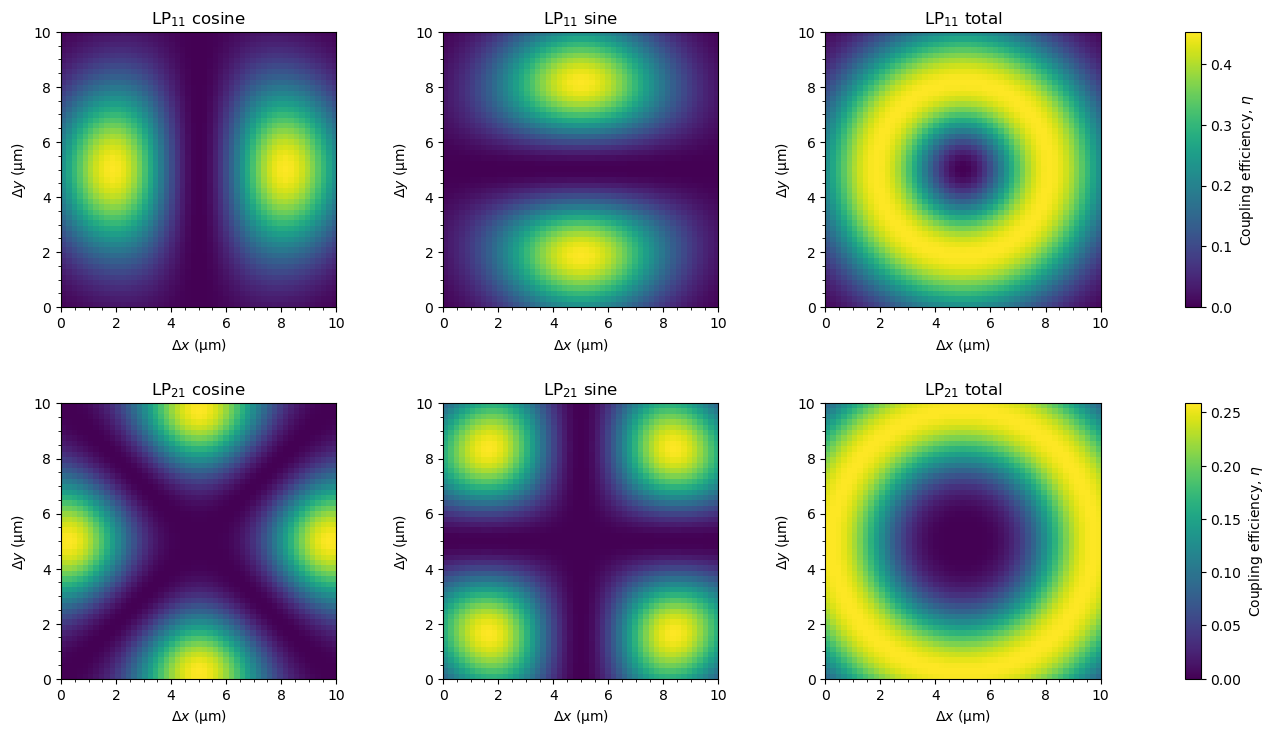

In [75]:
plot_selected_asymmetric_mode_family_maps(
    result["mode_eta_maps"],
    decentre_x_1d,
    decentre_y_1d,
    families=sorted({(l, m)
    for (l, m, angular) in result["mode_eta_maps"].keys()
    if l != 0})
)

In [70]:
def eta_psf_2d_decentre_map(
        prepared_modes,
        x, y, x_1d, y_1d,
        lam0, F_eff, alpha,
        decentre_x_1d,
        decentre_y_1d,
        E_S=1.0,
        return_mode_maps=False,
        n_jobs=1
):
    """
    Calculate point-source coupling efficiency over a 2D grid
    of PSF decentre positions.
    """

    nx = len(decentre_x_1d)
    ny = len(decentre_y_1d)

    # ---------------------------------------------------------
    # Prepare storage for individual mode maps
    # ---------------------------------------------------------

    if return_mode_maps:

        mode_eta_maps = {}

        for mode in prepared_modes:

            key = (
                mode["l"],
                mode["m"],
                mode["angular"]
            )

            mode_eta_maps[key] = np.zeros(
                (ny, nx)
            )

    else:

        mode_eta_maps = None

    # ---------------------------------------------------------
    # Calculate one horizontal row
    # ---------------------------------------------------------

    def calculate_row(dy):

        eta_row = np.zeros(nx)

        if return_mode_maps:

            mode_rows = {
                key: np.zeros(nx)
                for key in mode_eta_maps.keys()
            }

        else:

            mode_rows = None

        for ix, dx in enumerate(decentre_x_1d):

            eta_total, mode_results = total_eff_2d(
                prepared_modes=prepared_modes,
                x=x,
                y=y,
                x_1d=x_1d,
                y_1d=y_1d,
                lam0=lam0,
                F_eff=F_eff,
                alpha=alpha,
                decentre=(dx, dy),
                E_S=E_S
            )

            eta_row[ix] = eta_total

            if return_mode_maps:

                for result in mode_results:

                    key = (
                        result["l"],
                        result["m"],
                        result["angular"]
                    )

                    mode_rows[key][ix] = (
                        result["eta"]
                    )

        return eta_row, mode_rows

    # ---------------------------------------------------------
    # Calculate every y row
    # ---------------------------------------------------------

    if n_jobs == 1:

        eta_total_map = np.zeros(
            (ny, nx)
        )

        for iy, dy in enumerate(
                decentre_y_1d
        ):

            eta_row, mode_rows = (
                calculate_row(dy)
            )

            eta_total_map[iy, :] = (
                eta_row
            )

            if return_mode_maps:

                for key in mode_eta_maps:

                    mode_eta_maps[key][
                        iy, :
                    ] = mode_rows[key]

            print(
                f"{iy + 1}/{ny} rows complete "
                f"({100 * (iy + 1) / ny:.1f}%)"
            )

    else:

        results = Parallel(
            n_jobs=n_jobs,
            verbose=10
        )(
            delayed(calculate_row)(dy)
            for dy in decentre_y_1d
        )

        eta_total_map = np.array([
            result[0]
            for result in results
        ])

        if return_mode_maps:

            for key in mode_eta_maps:

                mode_eta_maps[key] = np.array([
                    result[1][key]
                    for result in results
                ])

    return eta_total_map, mode_eta_maps

In [86]:
import matplotlib.pyplot as plt
import numpy as np


def plot_selected_asymmetric_mode_family_maps(
        mode_maps,
        a,
        families,
        cmap="viridis",
        same_scale_per_row=True,
        show_core_boundary=True,
        mask_outside_core=False
):
    """
    Plot cosine, sine, and total coupling-efficiency maps for
    selected asymmetric LP mode families.

    The maps are plotted in PSF decentre space.

    Parameters
    ----------
    mode_maps : dict
        Dictionary with keys:
            (l, m, "cos")
            (l, m, "sin")

        Each value is a 2D coupling-efficiency map.

    a : float
        Fibre core radius [m].

    families : list of tuple
        Mode families to plot, e.g.
            [(1, 1), (2, 1)]

    cmap : str
        Matplotlib colormap.

    same_scale_per_row : bool
        If True, use the same colour scale for cosine,
        sine, and total maps within each mode family.

    show_core_boundary : bool
        If True, overlay the adopted r = a boundary.

    mask_outside_core : bool
        If True, set map values outside r > a to NaN.
    """

    nrows = len(families)

    # ----------------------------------------------------------
    # Determine map size and reconstruct decentre coordinates
    # ----------------------------------------------------------

    first_key = next(iter(mode_maps))
    ny, nx = mode_maps[first_key].shape

    decentre_x_1d = np.linspace(
        -a,
        a,
        nx
    )

    decentre_y_1d = np.linspace(
        -a,
        a,
        ny
    )

    DX, DY = np.meshgrid(
        decentre_x_1d,
        decentre_y_1d
    )

    R = np.sqrt(
        DX**2 + DY**2
    )

    # Convert coordinates to microns for plotting
    a_um = a * 1e6

    extent = [
        -a_um,
        +a_um,
        -a_um,
        +a_um
    ]

    # ----------------------------------------------------------
    # Figure layout
    # ----------------------------------------------------------

    fig = plt.figure(
        figsize=(15, 4.2 * nrows)
    )

    gs = fig.add_gridspec(
        nrows=nrows,
        ncols=4,
        width_ratios=[1, 1, 1, 0.05],
        wspace=0.25,
        hspace=0.35
    )

    # ----------------------------------------------------------
    # Loop over selected mode families
    # ----------------------------------------------------------

    for i, (l, m) in enumerate(families):

        eta_cos = mode_maps[
            (l, m, "cos")
        ].copy()

        eta_sin = mode_maps[
            (l, m, "sin")
        ].copy()

        eta_total = (
            eta_cos + eta_sin
        )

        # ------------------------------------------------------
        # Optional circular mask
        # ------------------------------------------------------

        if mask_outside_core:

            outside = R > a

            eta_cos[outside] = np.nan
            eta_sin[outside] = np.nan
            eta_total[outside] = np.nan

        maps = [
            eta_cos,
            eta_sin,
            eta_total
        ]

        titles = [
            rf"LP$_{{{l}{m}}}$ cosine",
            rf"LP$_{{{l}{m}}}$ sine",
            rf"LP$_{{{l}{m}}}$ total"
        ]

        # ------------------------------------------------------
        # Colour scale
        # ------------------------------------------------------

        if same_scale_per_row:

            vmax = np.nanmax([
                np.nanmax(eta_cos),
                np.nanmax(eta_sin),
                np.nanmax(eta_total)
            ])

            vmin = 0.0

        else:

            vmin = None
            vmax = None

        # ------------------------------------------------------
        # Plot cosine, sine, total
        # ------------------------------------------------------

        for j in range(3):

            ax = fig.add_subplot(
                gs[i, j]
            )

            im = ax.imshow(
                maps[j],
                extent=extent,
                origin="lower",
                aspect="equal",
                cmap=cmap,
                vmin=vmin,
                vmax=vmax
            )

            ax.set_title(
                titles[j]
            )

            ax.set_xlabel(
                r"$\Delta x$ ($\mu$m)"
            )

            ax.set_ylabel(
                r"$\Delta y$ ($\mu$m)"
            )

            ax.minorticks_on()

            # --------------------------------------------------
            # Fibre/core-radius boundary in decentre space
            # --------------------------------------------------

            if show_core_boundary:

                theta = np.linspace(
                    0,
                    2 * np.pi,
                    400
                )

                ax.plot(
                    a_um * np.cos(theta),
                    a_um * np.sin(theta),
                    linestyle="--",
                    linewidth=1.5,
                    color="white"
                )

            # Mark fibre centre
            ax.plot(
                0,
                0,
                marker="+",
                markersize=8,
                color="white"
            )

        # ------------------------------------------------------
        # One colourbar per row
        # ------------------------------------------------------

        cax = fig.add_subplot(
            gs[i, 3]
        )

        cbar = fig.colorbar(
            im,
            cax=cax
        )

        cbar.set_label(
            r"Coupling efficiency, $\eta$"
        )

    plt.show()

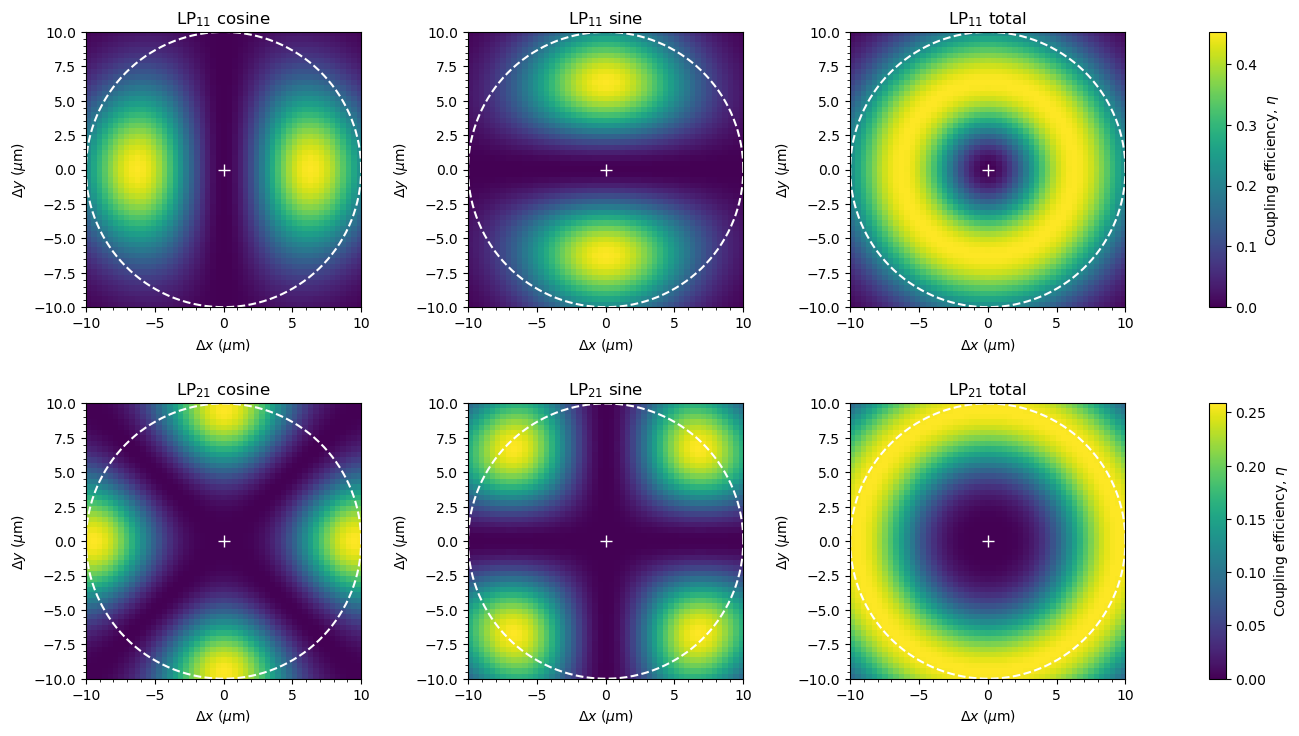

In [77]:
plot_selected_asymmetric_mode_family_maps(
    mode_maps=result["mode_eta_maps"],
    a=result["a"],
    families=[
        (1, 1),
        (2, 1)
    ],
    show_core_boundary=True,
    mask_outside_core=False
)

In [78]:
def psf_2d_decentre_map(
        a,
        x, y,
        x_1d, y_1d,
        lam0,
        NA,
        F_eff,
        alpha,
        n_decentre=51,
        E_S=1.0,
        mode_case="few_mode",
        n_jobs=1
):

    prepared_modes = prepare_modes_2d(
        x, y,
        a=a,
        NA=NA,
        lam0=lam0,
        az_sym=False,
        mode_case=mode_case
    )

    # Separate from the ±125 µm overlap-integral grid.
    decentre_max = a

    decentre_x_1d = np.linspace(
        -decentre_max,
        decentre_max,
        n_decentre
    )

    decentre_y_1d = np.linspace(
        -decentre_max,
        decentre_max,
        n_decentre
    )

    eta_total_map, mode_eta_maps = eta_psf_2d_decentre_map(
        prepared_modes=prepared_modes,
        x=x,
        y=y,
        x_1d=x_1d,
        y_1d=y_1d,
        lam0=lam0,
        F_eff=F_eff,
        alpha=alpha,
        decentre_x_1d=decentre_x_1d,
        decentre_y_1d=decentre_y_1d,
        E_S=E_S,
        return_mode_maps=True,
        n_jobs=n_jobs
    )

    return {
        "a": a,
        "eta_total_map": eta_total_map,
        "mode_eta_maps": mode_eta_maps
    }

In [79]:
import time
import numpy as np


def eta_maps_vs_core_radius(
        core_radius_array,
        x, y,
        x_1d, y_1d,
        NA,
        lam0,
        alpha,
        F_eff,
        n_decentre=51,
        mode_case="few_mode",
        E_S=1.0,
        n_jobs=1
):
    """
    Calculate 2D point-source coupling-efficiency maps
    for a sequence of fibre core radii.

    Core radii are processed serially.

    For each fibre radius a:
        1. psf_2d_decentre_map() prepares the supported modes.
        2. It defines the PSF decentre grid from -a to +a.
        3. It calculates the total and individual-mode 2D maps.
        4. The result is stored in a list.

    Parameters
    ----------
    core_radius_array : 1D array
        Fibre core radii [m].

    x, y : 2D arrays
        Fixed overlap-integral grid [m].

    x_1d, y_1d : 1D arrays
        Fixed overlap-integral coordinate axes [m].

    NA : float
        Fibre numerical aperture.

    lam0 : float
        Wavelength [m].

    alpha : float
        Central obstruction ratio.

    F_eff : float
        Effective focal ratio.

    n_decentre : int
        Number of PSF-decentre samples along each axis.
        Odd values are recommended so that (0,0) is sampled.

    mode_case : str
        Mode-selection case.

    E_S : float
        Source electric-field amplitude.

    n_jobs : int
        Number of parallel workers used INSIDE each 2D map
        calculation.

    Returns
    -------
    results_all_radius : list of dict

        Each entry contains:

        {
            "a": fibre core radius,
            "eta_total_map": 2D array,
            "mode_eta_maps": {
                (l, m, angular): 2D array
            }
        }
    """

    core_radius_array = np.asarray(
        core_radius_array
    )

    n_total = len(core_radius_array)

    results_all_radius = []

    start_time = time.time()

    # ---------------------------------------------------------
    # Loop serially over fibre core radius
    # ---------------------------------------------------------

    for i, a in enumerate(core_radius_array):

        print(
            f"\nCore radius = "
            f"{a * 1e6:.2f} µm "
            f"({i + 1}/{n_total})"
        )

        # Physical PSF-decentre spacing for THIS radius
        decentre_step = (
            2 * a / (n_decentre - 1)
        )

        print(
            f"Decentre range: "
            f"{-a * 1e6:.2f} to "
            f"{a * 1e6:.2f} µm"
        )

        print(
            f"Decentre spacing: "
            f"{decentre_step * 1e6:.3f} µm"
        )

        # -----------------------------------------------------
        # Calculate the coupling maps for this radius
        # -----------------------------------------------------

        result = psf_2d_decentre_map(
            a=a,
            x=x,
            y=y,
            x_1d=x_1d,
            y_1d=y_1d,
            lam0=lam0,
            NA=NA,
            F_eff=F_eff,
            alpha=alpha,
            n_decentre=n_decentre,
            E_S=E_S,
            mode_case=mode_case,
            n_jobs=n_jobs
        )

        results_all_radius.append(
            result
        )

        # -----------------------------------------------------
        # Progress
        # -----------------------------------------------------

        elapsed_time = (
            time.time() - start_time
        )

        elapsed_minutes = int(
            elapsed_time // 60
        )

        elapsed_seconds = int(
            elapsed_time % 60
        )

        percent = int(
            round(
                100 * (i + 1) / n_total
            )
        )

        print(
            f"{percent}% complete "
            f"({i + 1}/{n_total}) | "
            f"elapsed: "
            f"{elapsed_minutes} min "
            f"{elapsed_seconds:02d} sec"
        )

    return results_all_radius

In [80]:
core_radius_test = np.array([
    10e-6,
    11e-6
])

results_test = eta_maps_vs_core_radius(
    core_radius_array=core_radius_test,
    x=x,
    y=y,
    x_1d=x_1d,
    y_1d=y_1d,
    NA=0.1,
    lam0=1.5e-6,
    alpha=0.125,
    F_eff=1 / (
        2 * np.tan(
            np.arcsin(0.1)
        )
    ),
    n_decentre=51,
    mode_case="few_mode",
    E_S=1.0,
    n_jobs=4
)


Core radius = 10.00 µm (1/2)
Decentre range: -10.00 to 10.00 µm
Decentre spacing: 0.400 µm


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:   24.3s
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:   33.6s
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:   50.0s
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:  1.0min
[Parallel(n_jobs=4)]: Done  33 tasks      | elapsed:  1.4min
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:  1.8min
[Parallel(n_jobs=4)]: Done  51 out of  51 | elapsed:  2.1min finished


50% complete (1/2) | elapsed: 2 min 05 sec

Core radius = 11.00 µm (2/2)
Decentre range: -11.00 to 11.00 µm
Decentre spacing: 0.440 µm


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:   18.7s
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:   28.8s
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:   50.8s
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:  1.1min
[Parallel(n_jobs=4)]: Done  33 tasks      | elapsed:  1.7min
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:  2.1min


100% complete (2/2) | elapsed: 4 min 37 sec


[Parallel(n_jobs=4)]: Done  51 out of  51 | elapsed:  2.5min finished


In [85]:
results_test[0]["mode_eta_maps"]

{(0,
  1,
  'cos'): array([[7.60048418e-09, 3.75885117e-05, 1.66014794e-04, ...,
         1.66015120e-04, 3.75886479e-05, 7.59889300e-09],
        [3.75885117e-05, 1.73984152e-04, 4.33793167e-04, ...,
         4.33794244e-04, 1.73984794e-04, 3.75887852e-05],
        [1.66014794e-04, 4.33793167e-04, 8.63877168e-04, ...,
         8.63879567e-04, 4.33794806e-04, 1.66015755e-04],
        ...,
        [1.66015120e-04, 4.33794244e-04, 8.63879567e-04, ...,
         8.63876983e-04, 4.33792581e-04, 1.66014191e-04],
        [3.75886479e-05, 1.73984794e-04, 4.33794806e-04, ...,
         4.33792581e-04, 1.73983486e-04, 3.75880856e-05],
        [7.59889300e-09, 3.75887852e-05, 1.66015755e-04, ...,
         1.66014191e-04, 3.75880856e-05, 7.60822212e-09]], shape=(51, 51)),
 (1,
  1,
  'cos'): array([[0.00686567, 0.00899175, 0.01135939, ..., 0.01135939, 0.00899175,
         0.00686567],
        [0.00975667, 0.01253316, 0.01558389, ..., 0.0155839 , 0.01253317,
         0.00975668],
        [0.01342082

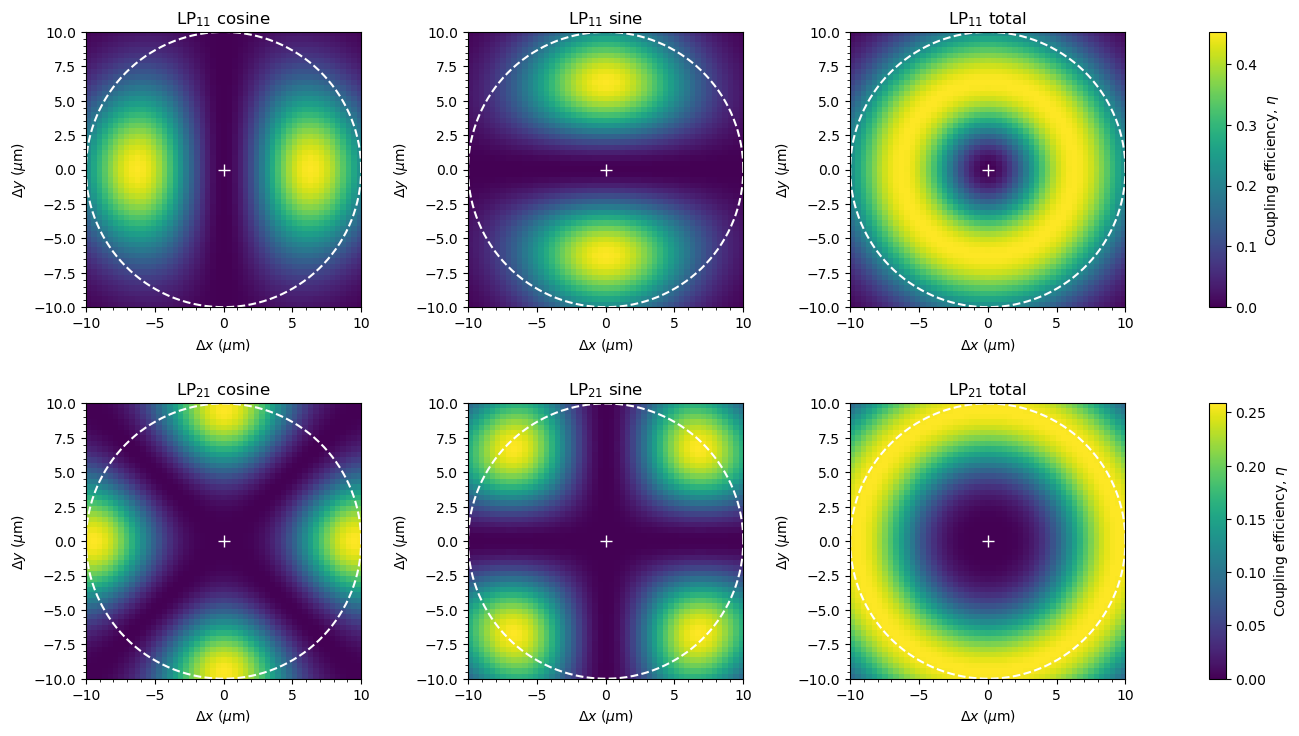

In [90]:
plot_selected_asymmetric_mode_family_maps(
    results_test[0]["mode_eta_maps"],
    a=10e-6,
    families=sorted({
        (l, m)
        for (l, m, angular)
        in results_test[0]["mode_eta_maps"].keys()
        if l != 0
    }),
)

In [91]:
import os
import psutil

process = psutil.Process(os.getpid())

ram_gb = process.memory_info().rss / 1024**3

print(f"Current notebook kernel RAM usage: {ram_gb:.2f} GB")

Current notebook kernel RAM usage: 0.04 GB
